In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

In [4]:
df = pd.read_csv("electric_vehicles_spec_2025.csv.csv")
df.head()

,brand,model,top_speed_kmh,battery_capacity_kWh,battery_type,number_of_cells,torque_nm,efficiency_wh_per_km,range_km,acceleration_0_100_s,...,towing_capacity_kg,cargo_volume_l,seats,drivetrain,segment,length_mm,width_mm,height_mm,car_body_type,source_url
0,Abarth,500e Convertible,155,37.8,Lithium-ion,192.0,235.0,156,225,7.0,...,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1904/Abarth-500e-C...
1,Abarth,500e Hatchback,155,37.8,Lithium-ion,192.0,235.0,149,225,7.0,...,0.0,185,4,FWD,B - Compact,3673,1683,1518,Hatchback,https://ev-database.org/car/1903/Abarth-500e-H...
2,Abarth,600e Scorpionissima,200,50.8,Lithium-ion,102.0,345.0,158,280,5.9,...,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3057/Abarth-600e-S...
3,Abarth,600e Turismo,200,50.8,Lithium-ion,102.0,345.0,158,280,6.2,...,0.0,360,5,FWD,JB - Compact,4187,1779,1557,SUV,https://ev-database.org/car/3056/Abarth-600e-T...
4,Aiways,U5,150,60.0,Lithium-ion,NaN,310.0,156,315,7.5,...,NaN,496,5,FWD,JC - Medium,4680,1865,1700,SUV,https://ev-database.org/car/1678/Aiways-U5


In [5]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("\nDataset information:")
df.info()

Dataset shape: (478, 22)
Number of rows: 478
Number of columns: 22

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 478 entries, 0 to 477
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   brand                      478 non-null    object 
 1   model                      477 non-null    object 
 2   top_speed_kmh              478 non-null    int64  
 3   battery_capacity_kWh       478 non-null    float64
 4   battery_type               478 non-null    object 
 5   number_of_cells            276 non-null    float64
 6   torque_nm                  471 non-null    float64
 7   efficiency_wh_per_km       478 non-null    int64  
 8   range_km                   478 non-null    int64  
 9   acceleration_0_100_s       478 non-null    float64
 10  fast_charging_power_kw_dc  477 non-null    float64
 11  fast_charge_port           477 non-null    object 
 12  towing_capacity_k

In [6]:
print("Missing values in each column:")
print(df.isnull().sum())
print("\nDrivetrain classes:")
print(df["drivetrain"].value_counts())

Missing values in each column:
brand                          0
model                          1
top_speed_kmh                  0
battery_capacity_kWh           0
battery_type                   0
number_of_cells              202
torque_nm                      7
efficiency_wh_per_km           0
range_km                       0
acceleration_0_100_s           0
fast_charging_power_kw_dc      1
fast_charge_port               1
towing_capacity_kg            26
cargo_volume_l                 1
seats                          0
drivetrain                     0
segment                        0
length_mm                      0
width_mm                       0
height_mm                      0
car_body_type                  0
source_url                     0
dtype: int64

Drivetrain classes:
drivetrain
AWD    191
FWD    156
RWD    131
Name: count, dtype: int64


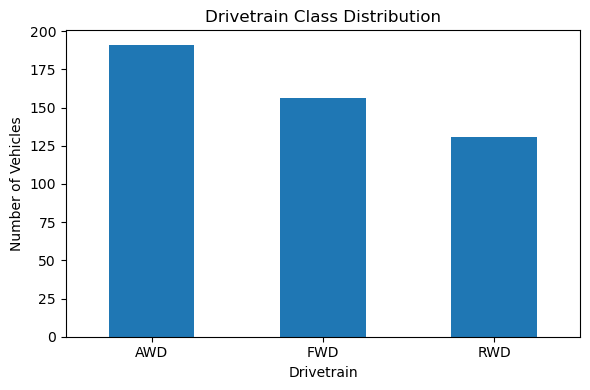

In [7]:
df["drivetrain"].value_counts().plot(kind="bar", figsize=(6, 4))
plt.title("Drivetrain Class Distribution")
plt.xlabel("Drivetrain")
plt.ylabel("Number of Vehicles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
df["cargo_volume_l"] = pd.to_numeric(df["cargo_volume_l"], errors="coerce")
X = df.select_dtypes(include="number").copy()
y = df["drivetrain"].copy()
print("Number of input features:", X.shape[1])
print("\nInput features:")
print(X.columns.tolist())
print("\nMissing values in the selected features:")
print(X.isnull().sum()[X.isnull().sum() > 0])

Number of input features: 14

Input features:
['top_speed_kmh', 'battery_capacity_kWh', 'number_of_cells', 'torque_nm', 'efficiency_wh_per_km', 'range_km', 'acceleration_0_100_s', 'fast_charging_power_kw_dc', 'towing_capacity_kg', 'cargo_volume_l', 'seats', 'length_mm', 'width_mm', 'height_mm']

Missing values in the selected features:
number_of_cells              202
torque_nm                      7
fast_charging_power_kw_dc      1
towing_capacity_kg            26
cargo_volume_l                 4
dtype: int64


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 382
Testing records: 96


In [10]:
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)
print("Missing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

Missing values in training data: 0
Missing values in testing data: 0


In [11]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
print("Model training completed successfully.")

Model training completed successfully.


In [12]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy Score:", round(accuracy, 4))
print("Accuracy Percentage: {:.2f}%".format(accuracy * 100))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy Score: 0.9062
Accuracy Percentage: 90.62%

Classification Report:
              precision    recall  f1-score   support

         AWD       0.91      1.00      0.95        39
         FWD       0.93      0.90      0.92        31
         RWD       0.87      0.77      0.82        26

    accuracy                           0.91        96
   macro avg       0.90      0.89      0.90        96
weighted avg       0.91      0.91      0.90        96



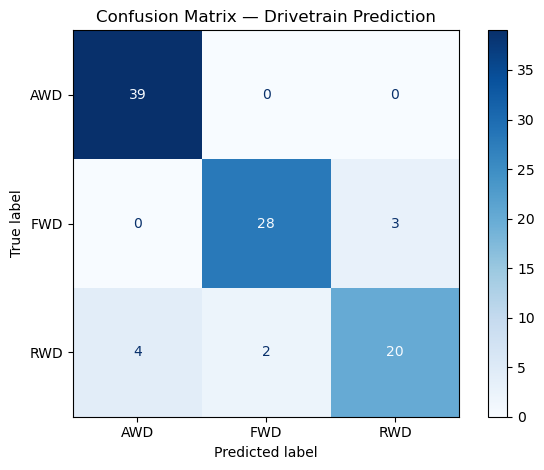

In [13]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=model.classes_,
    display_labels=model.classes_,
    cmap="Blues",
    values_format="d"
)
plt.title("Confusion Matrix — Drivetrain Prediction")
plt.tight_layout()
plt.show()